# Road Accident Severity Prediction

**Machine Learning Mini Project**

This notebook predicts the recorded severity label of a road accident: **Fatal injury**, **Serious Injury**, or **Slight Injury**.

> This is classification of recorded accidents, not prediction of whether an accident will happen.

## 1. Import libraries and load the dataset

Run this cell in Google Colab and upload `Road.csv`.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import joblib

from google.colab import files

uploaded = files.upload()
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset shape:", df.shape)
display(df.head())

Saving Road.csv to Road.csv
Dataset shape: (12316, 32)


,Time,Day_of_week,Age_band_of_driver,Sex_of_driver,Educational_level,Vehicle_driver_relation,Driving_experience,Type_of_vehicle,Owner_of_vehicle,Service_year_of_vehicle,...,Vehicle_movement,Casualty_class,Sex_of_casualty,Age_band_of_casualty,Casualty_severity,Work_of_casuality,Fitness_of_casuality,Pedestrian_movement,Cause_of_accident,Accident_severity
0,17:02:00,Monday,18-30,Male,Above high school,Employee,1-2yr,Automobile,Owner,Above 10yr,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Moving Backward,Slight Injury
1,17:02:00,Monday,31-50,Male,Junior high school,Employee,Above 10yr,Public (> 45 seats),Owner,5-10yrs,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury
2,17:02:00,Monday,18-30,Male,Junior high school,Employee,1-2yr,Lorry (41?100Q),Owner,NaN,...,Going straight,Driver or rider,Male,31-50,3,Driver,NaN,Not a Pedestrian,Changing lane to the left,Serious Injury
3,1:06:00,Sunday,18-30,Male,Junior high school,Employee,5-10yr,Public (> 45 seats),Governmental,NaN,...,Going straight,Pedestrian,Female,18-30,3,Driver,Normal,Not a Pedestrian,Changing lane to the right,Slight Injury
4,1:06:00,Sunday,18-30,Male,Junior high school,Employee,2-5yr,NaN,Owner,5-10yrs,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury


## 2. Inspect and clean the data

This checks the target distribution and missing values, converts common text placeholders to missing values, and removes only rows whose target label is missing. Feature missing values are handled later by the preprocessing pipeline.

In [ ]:
target = "Accident_severity"

if target not in df.columns:
    raise ValueError(f"Target column '{target}' was not found in the dataset.")

print("Target distribution before cleaning:")
display(df[target].value_counts(dropna=False).to_frame("Count"))

print("\nMissing values before cleaning:")
display(df.isna().sum().loc[lambda s: s > 0].sort_values(ascending=False).to_frame("Missing"))

placeholders = {"na", "n/a", "unknown", "none", "?"}
for col in df.select_dtypes(include=["object", "string"]).columns:
    values = df[col].astype("string").str.strip()
    df[col] = values.mask(
    values.str.lower().isin(placeholders), np.nan
).astype(object)

df = df.replace({pd.NA: np.nan})

df = df.dropna(subset=[target]).copy()

print("Shape after removing rows without target:", df.shape)
print("Duplicate rows present (not automatically removed):", int(df.duplicated().sum()))

print("\nTarget distribution after cleaning:")
display(df[target].value_counts().to_frame("Count"))

print("\nRemaining missing values:")
display(df.isna().sum().loc[lambda s: s > 0].sort_values(ascending=False).to_frame("Missing"))

Target distribution before cleaning:


,Count
Accident_severity,
Slight Injury,10415
Serious Injury,1743
Fatal injury,158



Missing values before cleaning:


,Missing
Defect_of_vehicle,4427
Service_year_of_vehicle,3928
Work_of_casuality,3198
Fitness_of_casuality,2635
Type_of_vehicle,950
Types_of_Junction,887
Driving_experience,829
Educational_level,741
Vehicle_driver_relation,579
Owner_of_vehicle,482


Shape after removing rows without target: (12316, 32)
Duplicate rows present (not automatically removed): 0

Target distribution after cleaning:


,Count
Accident_severity,
Slight Injury,10415
Serious Injury,1743
Fatal injury,158



Remaining missing values:


,Missing
Service_year_of_vehicle,6811
Sex_of_casualty,4443
Age_band_of_casualty,4443
Casualty_severity,4443
Casualty_class,4443
Defect_of_vehicle,4427
Work_of_casuality,3217
Fitness_of_casuality,2635
Age_band_of_driver,1548
Types_of_Junction,1078


## 3. Select features and split the data

The selected input columns exclude casualty-related fields and `Cause_of_accident`. `Number_of_vehicles_involved` is converted to a numeric count before splitting. The stratified split keeps the target-class proportions similar in train and test sets.

In [ ]:
features = [
    "Time",
    "Day_of_week",
    "Age_band_of_driver",
    "Sex_of_driver",
    "Educational_level",
    "Vehicle_driver_relation",
    "Driving_experience",
    "Type_of_vehicle",
    "Owner_of_vehicle",
    "Service_year_of_vehicle",
    "Defect_of_vehicle",
    "Area_accident_occured",
    "Lanes_or_Medians",
    "Road_allignment",
    "Types_of_Junction",
    "Road_surface_type",
    "Road_surface_conditions",
    "Light_conditions",
    "Weather_conditions",
    "Number_of_vehicles_involved",
    "Vehicle_movement"
]

missing_columns = [col for col in features + [target] if col not in df.columns]
if missing_columns:
    raise ValueError(f"Missing expected columns: {missing_columns}")

X = df[features].copy()
y = df[target].copy()

# This column represents a count; convert invalid values to missing.
X["Number_of_vehicles_involved"] = pd.to_numeric(
    X["Number_of_vehicles_involved"], errors="coerce"
)

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training records:", len(X_train))
print("Test records:", len(X_test))
print("Input features:", len(features))
print("\nTraining-set class counts:")
display(y_train.value_counts().to_frame("Count"))
print("\nTraining-set class distribution (%):")
display((y_train.value_counts(normalize=True) * 100).round(2).to_frame("Percent"))
print("\nMissing values in X_train:", int(X_train.isna().sum().sum()))
print("Missing values in X_test:", int(X_test.isna().sum().sum()))

Training records: 9852
Test records: 2464
Input features: 21

Training-set class counts:


,Count
Accident_severity,
Slight Injury,8331
Serious Injury,1394
Fatal injury,127



Training-set class distribution (%):


,Percent
Accident_severity,
Slight Injury,84.56
Serious Injury,14.15
Fatal injury,1.29



Missing values in X_train: 15591
Missing values in X_test: 3884


## 4. Build the preprocessing pipeline

Numeric features are median-imputed. Categorical features are imputed with their most frequent value and one-hot encoded. The preprocessor is placed inside each model pipeline so it is fitted only on the relevant training fold during cross-validation.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Identify feature types
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "string", "bool"]
).columns.tolist()

# Numeric preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="most_frequent",
        missing_values=np.nan
    )),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Numeric features:", numeric_features)
print("Categorical feature count:", len(categorical_features))
print("Preprocessing pipeline ready.")

Numeric features: ['Number_of_vehicles_involved']
Categorical feature count: 20
Preprocessing pipeline ready.


## 5. Compare classification models with cross-validation

Five-fold stratified cross-validation is performed on the training set only. Macro F1 and balanced accuracy are important because the target classes are imbalanced. The test set is not used in model selection.

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Majority Baseline": DummyClassifier(strategy="most_frequent"),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced", max_depth=10,
        min_samples_leaf=10, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=150, class_weight="balanced",
        random_state=42, n_jobs=1
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "Logistic Regression": LogisticRegression(
        class_weight="balanced", max_iter=2000, random_state=42
    ),
    "SVM": SVC(class_weight="balanced", random_state=42)
}

scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "macro_f1": "f1_macro"
}

comparison_rows = []
for name, classifier in models.items():
    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", classifier)
    ])
    scores = cross_validate(
        pipeline, X_train, y_train,
        cv=cv, scoring=scoring, n_jobs=1
    )
    comparison_rows.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Balanced accuracy": scores["test_balanced_accuracy"].mean(),
        "Macro F1": scores["test_macro_f1"].mean()
    })

cv_results = pd.DataFrame(comparison_rows).sort_values(
    "Macro F1", ascending=False
).reset_index(drop=True)

display(cv_results.round(4))

,Model,Accuracy,Balanced accuracy,Macro F1
0,SVM,0.6941,0.5003,0.4808
1,Gradient Boosting,0.8507,0.4350,0.4510
2,Logistic Regression,0.6680,0.6162,0.4487
3,Decision Tree,0.6808,0.4736,0.3780
4,Random Forest,0.8458,0.3340,0.3069
5,Majority Baseline,0.8456,0.3333,0.3055


## 6. Tune and train the SVM model

The application uses an SVM classifier, so this section compares a small set of `C` values using cross-validation on the training data. The best value is selected by mean Macro F1, and the chosen pipeline is then fitted on all of `X_train`.

In [ ]:
tuning_rows = []

for c_value in [0.1, 1, 10]:
    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", SVC(
            C=c_value,
            class_weight="balanced",
            random_state=42
        ))
    ])
    scores = cross_validate(
        pipeline, X_train, y_train,
        cv=cv, scoring=scoring, n_jobs=1
    )
    tuning_rows.append({
        "C": c_value,
        "Accuracy": scores["test_accuracy"].mean(),
        "Balanced accuracy": scores["test_balanced_accuracy"].mean(),
        "Macro F1": scores["test_macro_f1"].mean()
    })

tuning_results = pd.DataFrame(tuning_rows).sort_values(
    "Macro F1", ascending=False
).reset_index(drop=True)

display(tuning_results.round(4))

best_c = float(tuning_results.iloc[0]["C"])
print("Selected SVM C:", best_c)

final_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", SVC(
        C=best_c,
        class_weight="balanced",
        random_state=42
    ))
])
final_model.fit(X_train, y_train)
print("Final SVM trained.")

,C,Accuracy,Balanced accuracy,Macro F1
0,10.0,0.8101,0.4913,0.5220
1,1.0,0.6941,0.5003,0.4808
2,0.1,0.5570,0.4666,0.3410


Selected SVM C: 10.0
Final SVM trained.


## 7. Evaluate the final SVM on the held-out test set

These metrics are calculated once on the test set, which was not used for cross-validation model selection or tuning. Check the per-class results carefully, especially for `Fatal injury`.

Test accuracy: 0.8231
Test balanced accuracy: 0.5016
Test Macro F1: 0.5331

Classification report:
                precision    recall  f1-score   support

  Fatal injury       0.60      0.19      0.29        31
Serious Injury       0.41      0.41      0.41       349
 Slight Injury       0.89      0.90      0.90      2084

      accuracy                           0.82      2464
     macro avg       0.63      0.50      0.53      2464
  weighted avg       0.82      0.82      0.82      2464



,Predicted: Fatal injury,Predicted: Serious Injury,Predicted: Slight Injury
Actual: Fatal injury,6,6,19
Actual: Serious Injury,0,143,206
Actual: Slight Injury,4,201,1879


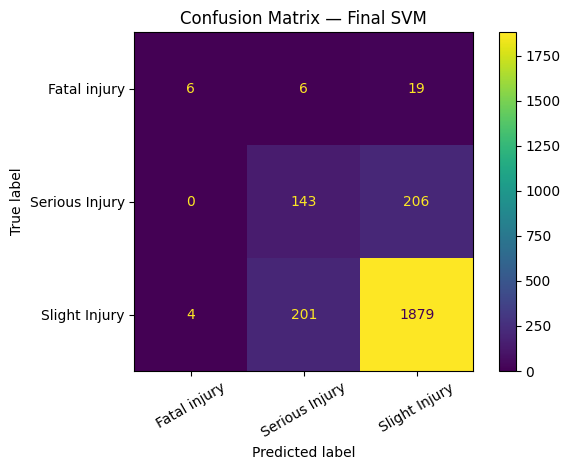

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

y_pred = final_model.predict(X_test)

print(f"Test accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Test balanced accuracy: {balanced_accuracy_score(y_test, y_pred):.4f}")
print(f"Test Macro F1: {f1_score(y_test, y_pred, average='macro'):.4f}")

print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

labels = list(final_model.named_steps["model"].classes_)
cm = confusion_matrix(y_test, y_pred, labels=labels)
display(pd.DataFrame(
    cm,
    index=[f"Actual: {label}" for label in labels],
    columns=[f"Predicted: {label}" for label in labels]
))

ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=labels
).plot(xticks_rotation=30)
plt.title("Confusion Matrix — Final SVM")
plt.tight_layout()
plt.show()

## 8. Compare imbalance-handling experiments

These experiments use the same train/test split. Resampling is performed only on training data and inside the pipeline, so the test set remains unchanged. These results are holdout comparisons; do not compare them as if they were cross-validation scores.

In [ ]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler
from imblearn.ensemble import BalancedRandomForestClassifier
from sklearn.metrics import classification_report, balanced_accuracy_score, f1_score

imbalance_models = {
    "Random Forest + RandomOverSampler": ImbPipeline([
        ("preprocessor", clone(preprocessor)),
        ("sampler", RandomOverSampler(random_state=42)),
        ("model", RandomForestClassifier(
            n_estimators=200, random_state=42, n_jobs=-1
        ))
    ]),
    "Balanced Random Forest": ImbPipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", BalancedRandomForestClassifier(
            n_estimators=200, random_state=42, n_jobs=-1
        ))
    ])
}

imbalance_results = []
imbalance_predictions = {}

for name, estimator in imbalance_models.items():
    estimator.fit(X_train, y_train)
    predictions = estimator.predict(X_test)
    imbalance_predictions[name] = predictions
    bal_acc = balanced_accuracy_score(y_test, predictions)
    macro_f1 = f1_score(y_test, predictions, average="macro")
    imbalance_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced accuracy": bal_acc,
        "Macro F1": macro_f1
    })
    print("\n" + name)
    print(classification_report(y_test, predictions, zero_division=0))

imbalance_results = pd.DataFrame(imbalance_results).sort_values(
    "Macro F1", ascending=False
).reset_index(drop=True)
display(imbalance_results.round(4))


Random Forest + RandomOverSampler
                precision    recall  f1-score   support

  Fatal injury       1.00      0.10      0.18        31
Serious Injury       0.89      0.02      0.04       349
 Slight Injury       0.85      1.00      0.92      2084

      accuracy                           0.85      2464
     macro avg       0.91      0.37      0.38      2464
  weighted avg       0.86      0.85      0.79      2464


Balanced Random Forest
                precision    recall  f1-score   support

  Fatal injury       0.11      0.42      0.17        31
Serious Injury       0.20      0.41      0.27       349
 Slight Injury       0.88      0.69      0.78      2084

      accuracy                           0.65      2464
     macro avg       0.40      0.51      0.41      2464
  weighted avg       0.78      0.65      0.70      2464



,Model,Accuracy,Balanced accuracy,Macro F1
0,Balanced Random Forest,0.6485,0.5070,0.4060
1,Random Forest + RandomOverSampler,0.8498,0.3731,0.3799


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

logistic_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)
y_pred_logistic = logistic_model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred_logistic), 4))
print("Balanced Accuracy:", round(
    balanced_accuracy_score(y_test, y_pred_logistic), 4
))
print("Macro F1:", round(
    f1_score(y_test, y_pred_logistic, average="macro"), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_logistic, zero_division=0
))

Accuracy: 0.6684
Balanced Accuracy: 0.6378
Macro F1: 0.4526

Classification Report:
                precision    recall  f1-score   support

  Fatal injury       0.13      0.68      0.22        31
Serious Injury       0.27      0.55      0.36       349
 Slight Injury       0.91      0.69      0.78      2084

      accuracy                           0.67      2464
     macro avg       0.43      0.64      0.45      2464
  weighted avg       0.81      0.67      0.72      2464



## 9. Save the final SVM and model comparison results

The saved model includes preprocessing and the trained SVM. The file name is compatible with the Streamlit application that loads this model.

In [ ]:
from pathlib import Path
import joblib

output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

model_path = output_dir / "road_accident_severity_model.joblib"
results_path = output_dir / "model_comparison.csv"
tuning_path = output_dir / "svm_hyperparameter_tuning_results.csv"
imbalance_path = output_dir / "imbalance_experiments.csv"

# Save the final tuned SVM pipeline
joblib.dump(final_model, model_path)

# Save the experimental results
cv_results.to_csv(results_path, index=False)
tuning_results.to_csv(tuning_path, index=False)
imbalance_results.to_csv(imbalance_path, index=False)

print("Saved model:", model_path)
print("Saved model comparison:", results_path)
print("Saved SVM tuning results:", tuning_path)
print("Saved imbalance experiments:", imbalance_path)

# Test the saved model's prediction capability
sample = X_test.iloc[[0]]

print("\nExample prediction:", final_model.predict(sample)[0])
display(sample)

Saved model: outputs/road_accident_severity_model.joblib
Saved model comparison: outputs/model_comparison.csv
Saved SVM tuning results: outputs/svm_hyperparameter_tuning_results.csv
Saved imbalance experiments: outputs/imbalance_experiments.csv

Example prediction: Slight Injury


,Time,Day_of_week,Age_band_of_driver,Sex_of_driver,Educational_level,Vehicle_driver_relation,Driving_experience,Type_of_vehicle,Owner_of_vehicle,Service_year_of_vehicle,...,Area_accident_occured,Lanes_or_Medians,Road_allignment,Types_of_Junction,Road_surface_type,Road_surface_conditions,Light_conditions,Weather_conditions,Number_of_vehicles_involved,Vehicle_movement
2671,13:25:00,Thursday,Over 51,Male,Junior high school,Employee,Below 1yr,Pick up upto 10Q,Owner,NaN,...,Other,Undivided Two way,Tangent road with flat terrain,Y Shape,Other,Dry,Daylight,Normal,2,Going straight


In [ ]:
import os

print("Files saved in outputs folder:")
for filename in sorted(os.listdir("outputs")):
    print(filename)

Files saved in outputs folder:
imbalance_experiments.csv
model_comparison.csv
road_accident_severity_model.joblib
svm_hyperparameter_tuning_results.csv


## 10. Download output files (Google Colab)

Run this cell if you want to download the saved model and result tables.

In [ ]:
import shutil
import os
from google.colab import files

# Check that the outputs folder exists
print("Files to include:", sorted(os.listdir("outputs")))

# Create a ZIP archive
shutil.make_archive("road_accident_outputs", "zip", "outputs")

# Download the ZIP archive
files.download("road_accident_outputs.zip")

Files to include: ['imbalance_experiments.csv', 'model_comparison.csv', 'road_accident_severity_model.joblib', 'svm_hyperparameter_tuning_results.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Conclusion and limitations

- The notebook compares several classifiers with stratified cross-validation and tunes the SVM using the training set.
- The final SVM is evaluated on a held-out test set.
- The target is imbalanced: `Slight Injury` is much more common than `Fatal injury`, so accuracy alone can be misleading.
- Review Fatal injury precision and recall before making claims about the model's usefulness for the rare class.
- `Number_of_vehicles_involved` is generally known after an accident has occurred. Therefore, this feature set is not a purely pre-accident warning system.
- The model should not be used as the sole basis for real-world safety decisions. Independent validation on other data is needed.

In [ ]:
import pandas as pd

print("Project Executed Successfully")

Project Executed Successfully
